In [2]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# DTI metrics
dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')
dti = dti[dti.isPatient == 1] # just patients
# normalize DTI metrics
dti.loc[dti.side == 'ipsilesional', 'ratio' ] = dti.loc[dti.side == 'ipsilesional', 'mean'].values /  dti.loc[dti.side == 'contralesional', 'mean'].values
dti = dti[(dti.regionname == 'CST_R') & (dti.metric == 'FaMap')]

/localscratch/tmp/ipykernel_30009/4002689481.py:9: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')


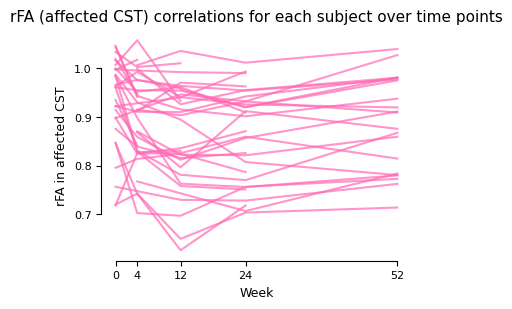

In [29]:
fig, ax = plt.subplots(figsize = (4,3))

sns.lineplot(x = 'Week', y = 'ratio', data = dti, units = 'subj_id', estimator = None, ax = ax, legend = False, alpha = .7, color = 'hotpink') # cool 'units' instead of 'hue'

ax.set_xticks(gl.weeks)
sns.despine(trim = True)
plt.title("rFA (affected CST) correlations for each subject over time points")
plt.ylabel("rFA in affected CST")
plt.show()